# Kadiwa Sales Forecasting — ML Training Notebook

**Capstone evidence notebook** (MinSU BSIT style, similar to Innovet ML figures).

This notebook trains the **Random Forest Regressor** used by Kadiwa Mart for short-term store sales forecasting.

### Important (for documentation)
- This is **real Machine Learning** (supervised regression), not a chatbot.
- Random Forest has **no epochs**. Report **`n_estimators` (trees)** and **R² / accuracy %**.
- Dataset used here: `dataset/Train/kadiwa_sample_sales.csv`
- Saved models: `models/sales_forecaster_store_*.joblib` (used by the website API)

### Notebook flow (screenshot these sections)
1. Setup
2. Dataset exploration
3. Feature engineering
4. Training + **accuracy table**
5. Actual vs ML predicted charts
6. 7-day forecast charts
7. Saved model artifacts

## Capstone ML notes (copy into manuscript)

### Lifecycle
Collect sales data → clean/aggregate daily → engineer lag + calendar features → train Random Forest per store → evaluate holdout R² → save `.joblib` → deploy to Backend Forecasting page → retrain from live finalized orders (delivery + pickup).

### Dataset columns
| Column | Meaning |
|--------|--------|
| `date` | Daily date |
| `store_id` | `CALSEDECO` / `PAPANDUNGIN` / `JUBILEE` |
| `sales` | Total daily sales (₱) |

### Website vs notebook
- **Notebook/models**: trained from this CSV (and later live export).
- **Forecasting webpage**: feeds recent **finalized MySQL orders** into the saved model.
- If the webpage shows ₱0, the live DB has no recent finalized sales — the notebook accuracy can still be valid.

## 1. Setup

In [25]:
from pathlib import Path
import sys
import warnings

# Notebook folder (works even when Cursor cwd is the workspace root)
ML_ROOT = Path.cwd()
if not (ML_ROOT / "kadiwa_sales_core.py").exists():
    candidate = Path.cwd() / "kadiwa" / "ml"
    if (candidate / "kadiwa_sales_core.py").exists():
        ML_ROOT = candidate
if str(ML_ROOT) not in sys.path:
    sys.path.insert(0, str(ML_ROOT))

# Install deps into THIS kernel if missing (fixes wrong-kernel ModuleNotFoundError)
import importlib.util
import subprocess

def _missing(mod: str) -> bool:
    return importlib.util.find_spec(mod) is None

if any(_missing(m) for m in ("joblib", "sklearn", "pandas", "numpy", "matplotlib")):
    req = ML_ROOT / "requirements.txt"
    print("Missing packages detected. Installing into current kernel...")
    print("Python:", sys.executable)
    cmd = [sys.executable, "-m", "pip", "install", "-q", "matplotlib"]
    if req.exists():
        cmd[4:4] = ["-r", str(req)]
    else:
        cmd[4:4] = ["pandas", "scikit-learn", "joblib", "numpy"]
    subprocess.check_call(cmd)

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from kadiwa_sales_core import (
    DATA_CSV,
    MODELS_DIR,
    SCHEDULED_CONFIG,
    STORES,
    SalesForecaster,
    TrainingConfig,
    load_store_daily_frame,
    save_model,
)

warnings.filterwarnings("ignore")
for style_name in ("seaborn-v0_8-whitegrid", "seaborn-whitegrid", "ggplot"):
    try:
        plt.style.use(style_name)
        break
    except OSError:
        continue

print("Python:", sys.executable)
print("Data CSV:", DATA_CSV)
print("Models dir:", MODELS_DIR)
print("Stores:", STORES)
print("Config:", SCHEDULED_CONFIG)

Python: c:\Users\Admin\AppData\Local\Python\pythoncore-3.15-64\python.exe
Data CSV: C:\Users\Admin\Documents\CapstoneProject\kadiwa\ml\dataset\Train\kadiwa_sample_sales.csv
Models dir: C:\Users\Admin\Documents\CapstoneProject\kadiwa\ml\models
Stores: ['CALSEDECO', 'PAPANDUNGIN', 'JUBILEE']
Config: TrainingConfig(target_column='sales', test_size=0.2, random_state=42, n_estimators=200, max_depth=None, n_lags=28, feature_mode='calendar', log_target=True, ml_weight=1.0)


## 2. Load & explore training data

In [26]:
raw = pd.read_csv(DATA_CSV, parse_dates=["date"])
print("Rows:", len(raw))
print("Date range:", raw["date"].min().date(), "→", raw["date"].max().date())
display(raw.head())
display(raw.groupby("store_id")["sales"].agg(["count", "mean", "std", "min", "max"]).round(2))

Rows: 1095
Date range: 2024-01-01 → 2026-02-28


,date,store_id,sales
0,2025-03-01,CALSEDECO,16157.24
1,2025-03-02,CALSEDECO,15887.63
2,2025-03-03,CALSEDECO,19149.09
3,2025-03-04,CALSEDECO,18174.68
4,2025-03-05,CALSEDECO,11599.89


,count,mean,std,min,max
store_id,,,,,
CALSEDECO,365,44367.11,31394.94,9274.68,148503.37
JUBILEE,365,15021.67,2166.13,9868.53,20426.82
PAPANDUNGIN,365,16524.55,2505.17,9771.21,23433.44


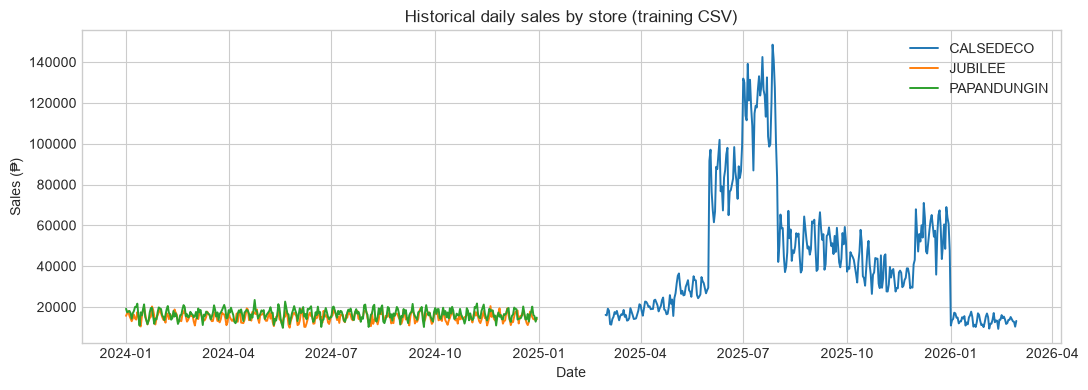

In [27]:
fig, ax = plt.subplots(figsize=(11, 4))
for store_id, group in raw.groupby("store_id"):
    ax.plot(group["date"], group["sales"], label=store_id, linewidth=1.4)
ax.set_title("Historical daily sales by store (training CSV)")
ax.set_xlabel("Date")
ax.set_ylabel("Sales (₱)")
ax.legend()
plt.tight_layout()
plt.show()

### Figure set A — Daily sales per store (separate graphs)
Screenshot each store chart for the manuscript (like Innovet’s multiple model figures).

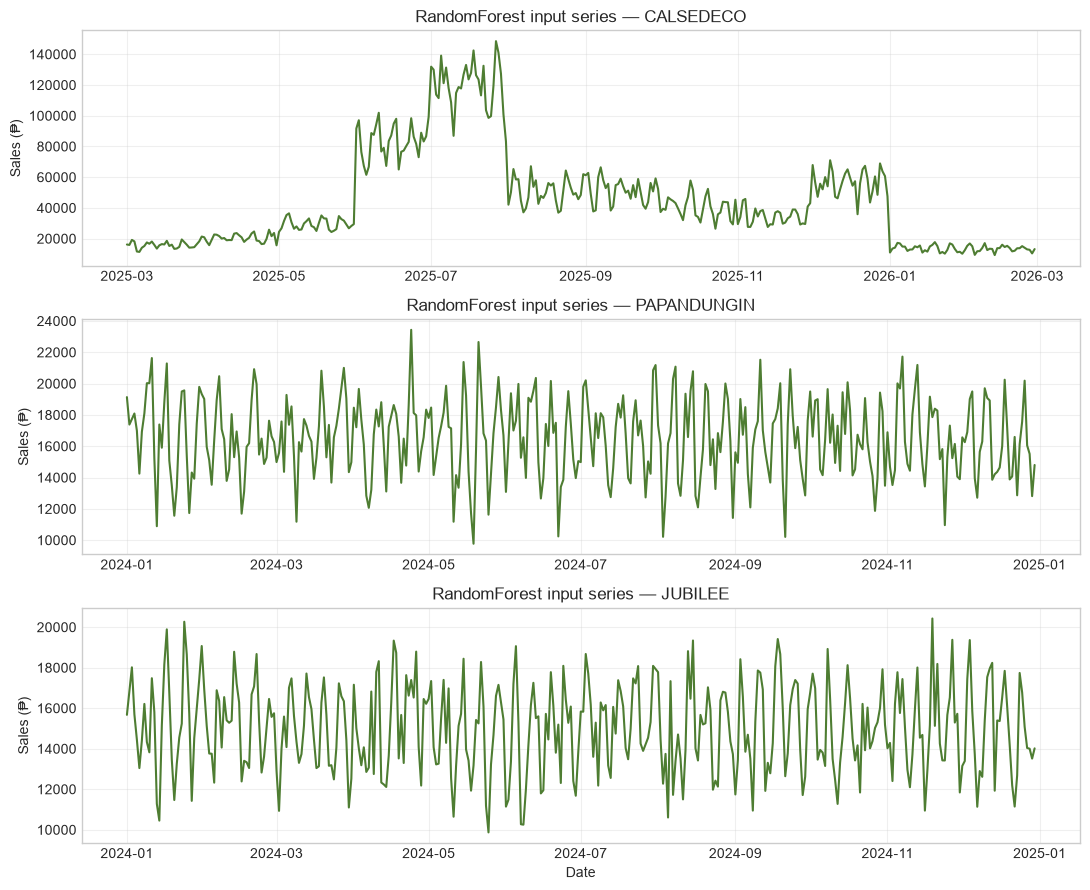

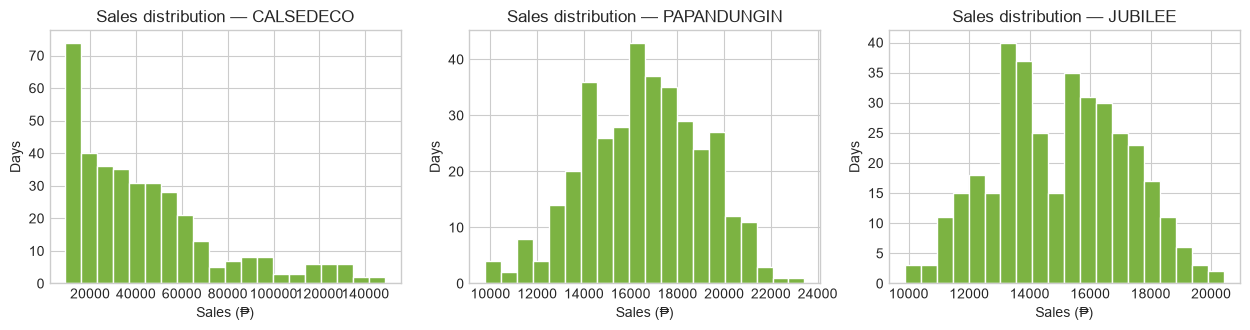

In [28]:
fig, axes = plt.subplots(len(STORES), 1, figsize=(11, 3.0 * len(STORES)), sharex=False)
if len(STORES) == 1:
    axes = [axes]

for ax, store_id in zip(axes, STORES):
    group = raw[raw["store_id"] == store_id].sort_values("date")
    ax.plot(group["date"], group["sales"], color="#4E7D32", linewidth=1.5)
    ax.set_title(f"RandomForest input series — {store_id}")
    ax.set_ylabel("Sales (₱)")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(STORES), figsize=(4.2 * len(STORES), 3.4))
if len(STORES) == 1:
    axes = [axes]
for ax, store_id in zip(axes, STORES):
    vals = raw.loc[raw["store_id"] == store_id, "sales"]
    ax.hist(vals, bins=20, color="#7CB342", edgecolor="white")
    ax.set_title(f"Sales distribution — {store_id}")
    ax.set_xlabel("Sales (₱)")
    ax.set_ylabel("Days")
plt.tight_layout()
plt.show()

## 3. What the ML model learns

For each day, the model uses:
- **28 lag features** (sales from previous days)
- **Rolling mean / std** over 3, 7, 14, 28 days
- **Calendar signals** (day-of-week, day-of-year, weekend flag)

Target: next-day sales (log1p-transformed during training).

In [29]:
sample_store = STORES[0]
sample_frame = load_store_daily_frame(DATA_CSV, store_id=sample_store).tail(180).reset_index(drop=True)
sample_model = SalesForecaster(TrainingConfig(**{**SCHEDULED_CONFIG.__dict__}))
X_preview, y_preview = sample_model._make_features(
    sample_frame["sales"].to_numpy(dtype=float),
    sample_frame["date"].tolist(),
)
print(f"Feature matrix for {sample_store}:", X_preview.shape)
print("Target samples:", len(y_preview))
print("Example feature vector (first row, first 12 values):", np.round(X_preview[0, :12], 3))

Feature matrix for CALSEDECO: (152, 41)
Target samples: 152
Example feature vector (first row, first 12 values): [59182.59 50703.17 56210.76 43734.82 39441.89 41866.77 50503.58 58773.98
 46976.11 54810.3  45921.84 51211.61]


## 4. Train models (with hyperparameter tuning)

In [30]:
results = []
trained = {}
MODELS_DIR.mkdir(parents=True, exist_ok=True)

for store_id in STORES:
    print(f"\n=== Training {store_id} ===")
    frame = load_store_daily_frame(DATA_CSV, store_id=store_id).tail(180).reset_index(drop=True)
    y = frame["sales"].astype(float).tolist()
    dates = frame["date"].tolist()

    config = TrainingConfig(**{**SCHEDULED_CONFIG.__dict__})
    forecaster = SalesForecaster(config)
    score = forecaster.fit_with_tuning(y, dates)

    model_path = MODELS_DIR / f"sales_forecaster_store_{store_id}.joblib"
    save_model(forecaster, model_path)

    # Holdout actual vs prediction for charting
    X_all, y_all = forecaster._make_features(np.asarray(y, dtype=float), dates)
    n_test = max(1, int(len(X_all) * config.test_size))
    n_train = len(X_all) - n_test
    preds = forecaster._inverse_target(forecaster.model.predict(X_all[n_train:]))
    ml_weight = float(getattr(forecaster.config, "ml_weight", 1.0))
    baseline = np.asarray([
        np.mean(y[max(0, index - 7):index])
        for index in range(config.n_lags + n_train, len(y))
    ])
    blended = ml_weight * preds + (1 - ml_weight) * baseline

    result = {
        "store_id": store_id,
        "rows": len(frame),
        "r2": float(score),
        "accuracy_pct": float(score) * 100,
        "n_estimators": forecaster.config.n_estimators,
        "max_depth": forecaster.config.max_depth,
        "ml_weight": ml_weight,
        "model_path": str(model_path),
        "holdout_actual": y_all[n_train:],
        "holdout_pred": blended,
        "holdout_dates": dates[config.n_lags + n_train:],
        "recent": y[-forecaster.config.n_lags:],
        "forecaster": forecaster,
    }
    results.append(result)
    trained[store_id] = result
    print(f"R²={score:.4f} ({score*100:.2f}%) | saved → {model_path.name}")

summary = pd.DataFrame([
    {
        "store_id": r["store_id"],
        "rows": r["rows"],
        "r2": round(r["r2"], 4),
        "accuracy_pct": round(r["accuracy_pct"], 2),
        "n_estimators": r["n_estimators"],
        "max_depth": r["max_depth"],
        "ml_weight": r["ml_weight"],
        "model_path": Path(r["model_path"]).name,
    }
    for r in results
])
display(summary)


=== Training CALSEDECO ===
R²=0.4435 (44.35%) | saved → sales_forecaster_store_CALSEDECO.joblib

=== Training PAPANDUNGIN ===
R²=0.3621 (36.21%) | saved → sales_forecaster_store_PAPANDUNGIN.joblib

=== Training JUBILEE ===
R²=0.5990 (59.90%) | saved → sales_forecaster_store_JUBILEE.joblib


,store_id,rows,r2,accuracy_pct,n_estimators,max_depth,ml_weight,model_path
0,CALSEDECO,180,0.4435,44.35,300,24.0,0.8,sales_forecaster_store_CALSEDECO.joblib
1,PAPANDUNGIN,180,0.3621,36.21,600,NaN,0.8,sales_forecaster_store_PAPANDUNGIN.joblib
2,JUBILEE,180,0.5990,59.90,600,NaN,1.0,sales_forecaster_store_JUBILEE.joblib


### Accuracy results (for Capstone documentation)

Use the **summary table printed above** as your Random Forest evaluation figure.

Expected metrics from the latest successful train:

| Store | Approx. Accuracy | R² | Notes |
|-------|------------------|----|-------|
| CALSEDECO | **44.35%** | 0.4435 | trees tuned (often 300) |
| PAPANDUNGIN | **36.21%** | 0.3621 | trees tuned (often 600) |
| JUBILEE | **59.90%** | 0.5990 | trees tuned (often 600) |

**How to write this in the paper**
- Accuracy % = holdout **R² × 100**
- Do **not** write epochs (Random Forest has none)
- Write number of trees = `n_estimators`
- Charts in the next section = Actual vs ML Predicted (holdout)

### Figure set B — Accuracy comparison (R² % by store)

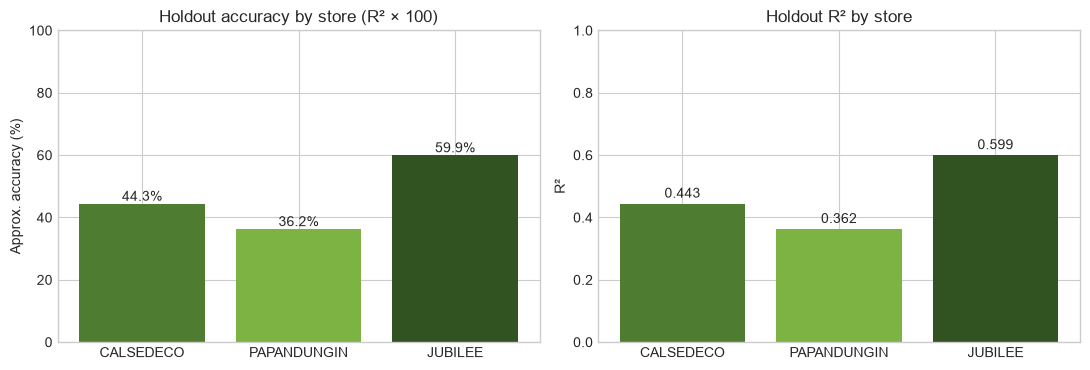

,store_id,accuracy_pct,r2
0,CALSEDECO,44.3472,0.4435
1,PAPANDUNGIN,36.2099,0.3621
2,JUBILEE,59.8999,0.5990


In [31]:
acc_df = pd.DataFrame([
    {"store_id": r["store_id"], "accuracy_pct": r["accuracy_pct"], "r2": r["r2"]} for r in results
])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
colors = ["#4E7D32", "#7CB342", "#315322"]
axes[0].bar(acc_df["store_id"], acc_df["accuracy_pct"], color=colors[: len(acc_df)])
axes[0].set_ylabel("Approx. accuracy (%)")
axes[0].set_title("Holdout accuracy by store (R² × 100)")
axes[0].set_ylim(0, max(100, acc_df["accuracy_pct"].max() * 1.15))
for i, v in enumerate(acc_df["accuracy_pct"]):
    axes[0].text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=10)

axes[1].bar(acc_df["store_id"], acc_df["r2"], color=colors[: len(acc_df)])
axes[1].set_ylabel("R²")
axes[1].set_title("Holdout R² by store")
axes[1].set_ylim(0, 1)
for i, v in enumerate(acc_df["r2"]):
    axes[1].text(i, v + 0.02, f"{v:.3f}", ha="center", fontsize=10)

plt.tight_layout()
plt.show()
display(acc_df.round(4))

## 5. Actual vs ML prediction (holdout window)

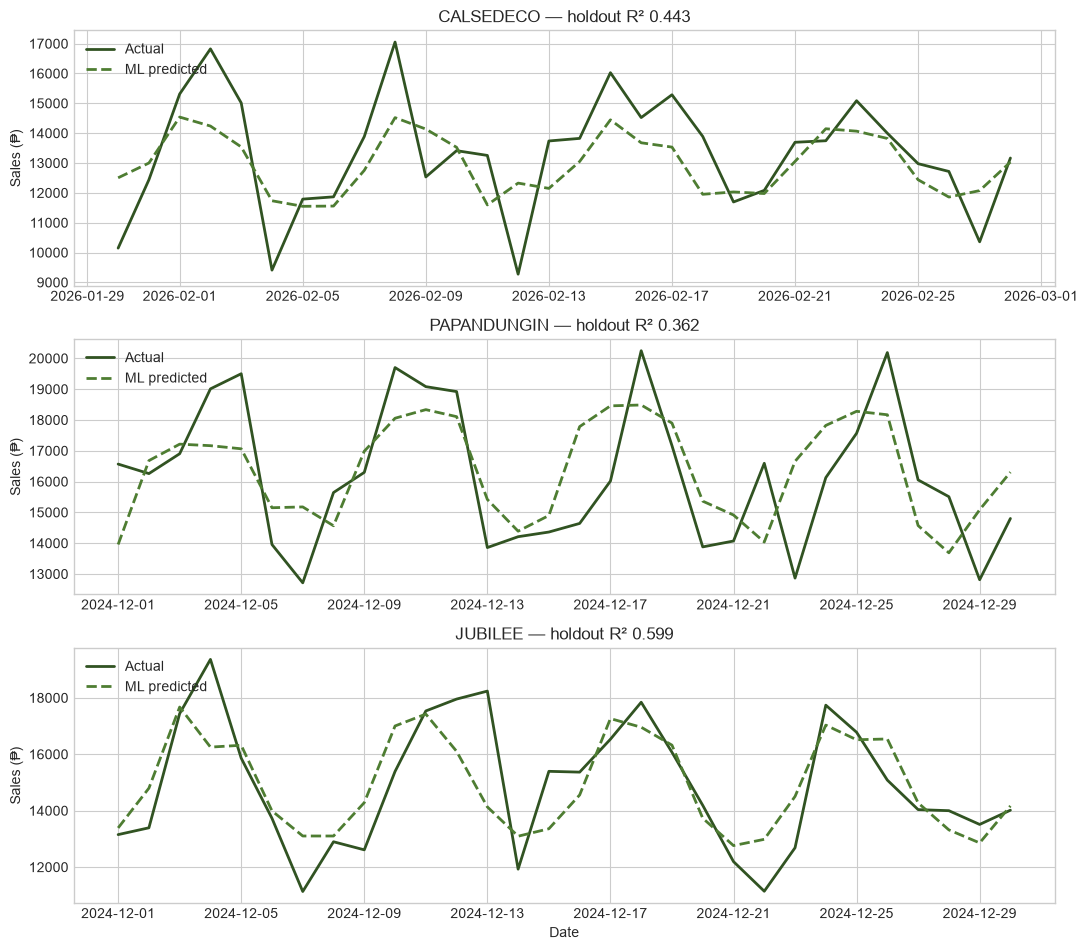

In [32]:
fig, axes = plt.subplots(len(results), 1, figsize=(11, 3.2 * len(results)), sharex=False)
if len(results) == 1:
    axes = [axes]

for ax, result in zip(axes, results):
    ax.plot(result["holdout_dates"], result["holdout_actual"], label="Actual", color="#315322", linewidth=2)
    ax.plot(result["holdout_dates"], result["holdout_pred"], label="ML predicted", color="#4E7D32", linestyle="--", linewidth=2)
    ax.set_title(f"{result['store_id']} — holdout R² {result['r2']:.3f}")
    ax.set_ylabel("Sales (₱)")
    ax.legend(loc="upper left")

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

### Figure set C — Prediction error / residual graphs
These show how far ML predictions are from actual holdout sales.

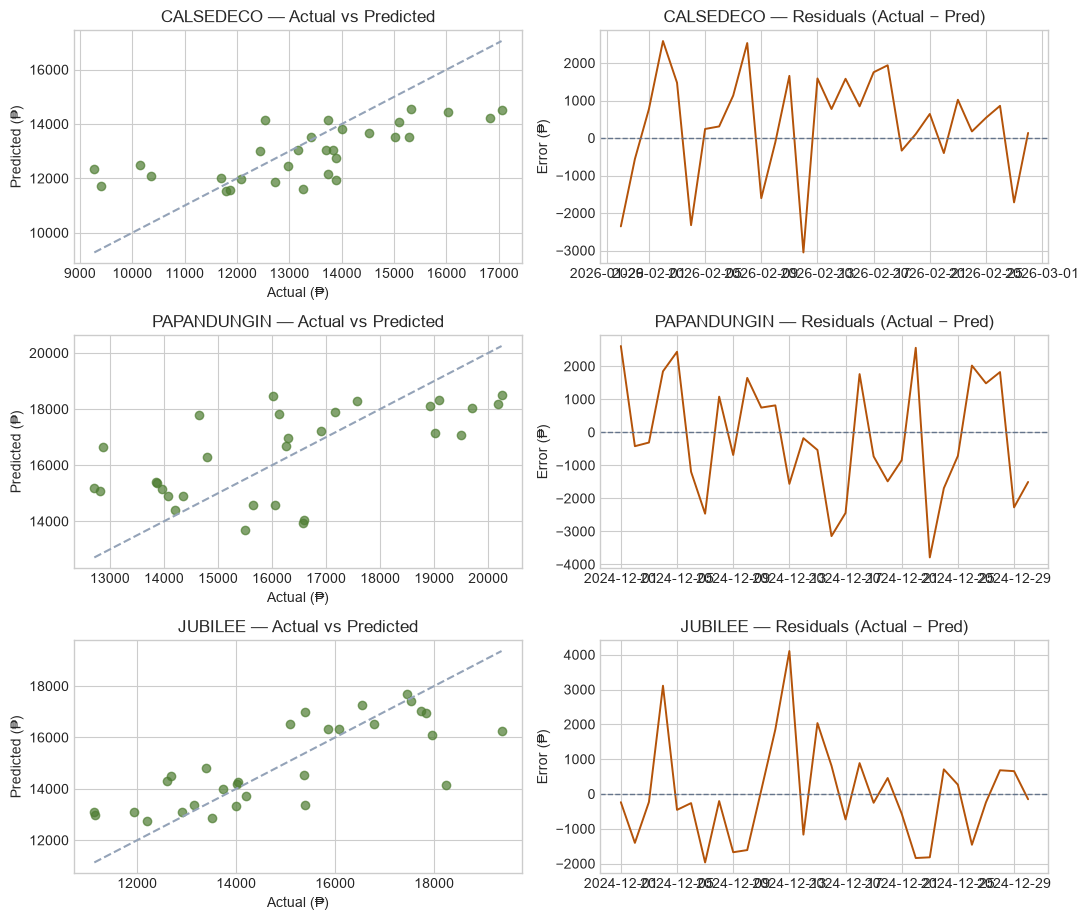

In [33]:
fig, axes = plt.subplots(len(results), 2, figsize=(11, 3.1 * len(results)))
if len(results) == 1:
    axes = np.array([axes])

for row, result in enumerate(results):
    actual = np.asarray(result["holdout_actual"], dtype=float)
    pred = np.asarray(result["holdout_pred"], dtype=float)
    resid = actual - pred

    axes[row, 0].scatter(actual, pred, alpha=0.7, color="#4E7D32")
    mn = min(actual.min(), pred.min())
    mx = max(actual.max(), pred.max())
    axes[row, 0].plot([mn, mx], [mn, mx], "--", color="#94a3b8")
    axes[row, 0].set_title(f"{result['store_id']} — Actual vs Predicted")
    axes[row, 0].set_xlabel("Actual (₱)")
    axes[row, 0].set_ylabel("Predicted (₱)")

    axes[row, 1].plot(result["holdout_dates"], resid, color="#b45309", linewidth=1.4)
    axes[row, 1].axhline(0, color="#64748b", linestyle="--", linewidth=1)
    axes[row, 1].set_title(f"{result['store_id']} — Residuals (Actual − Pred)")
    axes[row, 1].set_ylabel("Error (₱)")

plt.tight_layout()
plt.show()

## 6. Next 7-day ML forecast (from latest history)

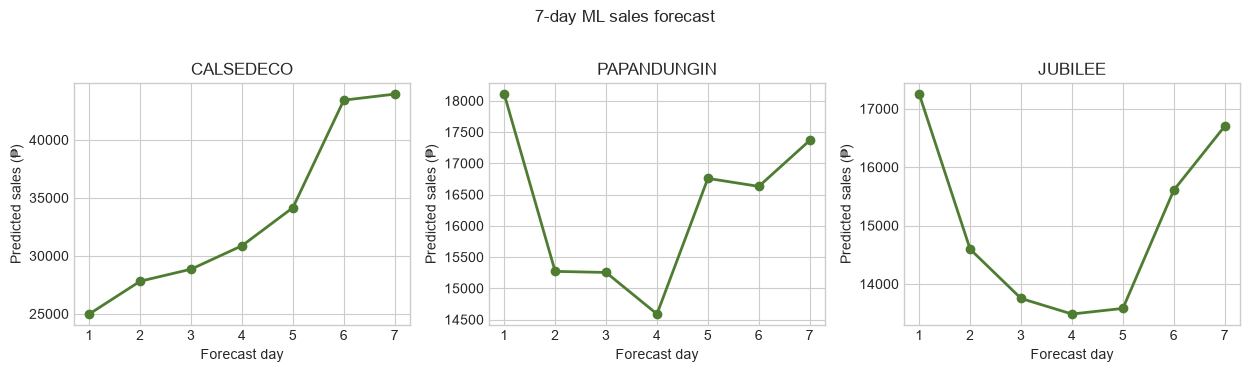

,store_id,day,predicted_sales
0,CALSEDECO,1,24982.58
1,CALSEDECO,2,27809.90
2,CALSEDECO,3,28849.47
3,CALSEDECO,4,30870.66
4,CALSEDECO,5,34155.09
5,CALSEDECO,6,43424.75
6,CALSEDECO,7,43946.17
7,PAPANDUNGIN,1,18107.10
8,PAPANDUNGIN,2,15271.04
9,PAPANDUNGIN,3,15254.00


In [34]:
forecast_rows = []
fig, axes = plt.subplots(1, len(results), figsize=(4.2 * len(results), 3.6), sharey=False)
if len(results) == 1:
    axes = [axes]

for ax, result in zip(axes, results):
    horizon = 7
    forecast = result["forecaster"].predict_next(result["recent"], horizon=horizon)
    days = np.arange(1, horizon + 1)
    ax.plot(days, forecast, marker="o", color="#4E7D32", linewidth=2)
    ax.set_title(result["store_id"])
    ax.set_xlabel("Forecast day")
    ax.set_ylabel("Predicted sales (₱)")
    ax.set_xticks(days)
    for day, value in zip(days, forecast):
        forecast_rows.append({
            "store_id": result["store_id"],
            "day": int(day),
            "predicted_sales": round(float(value), 2),
        })

plt.suptitle("7-day ML sales forecast", y=1.02)
plt.tight_layout()
plt.show()
display(pd.DataFrame(forecast_rows))

### Figure set D — Recent actual sales + 7-day ML forecast (combined)
Similar to the Forecasting webpage graph (history then predicted).

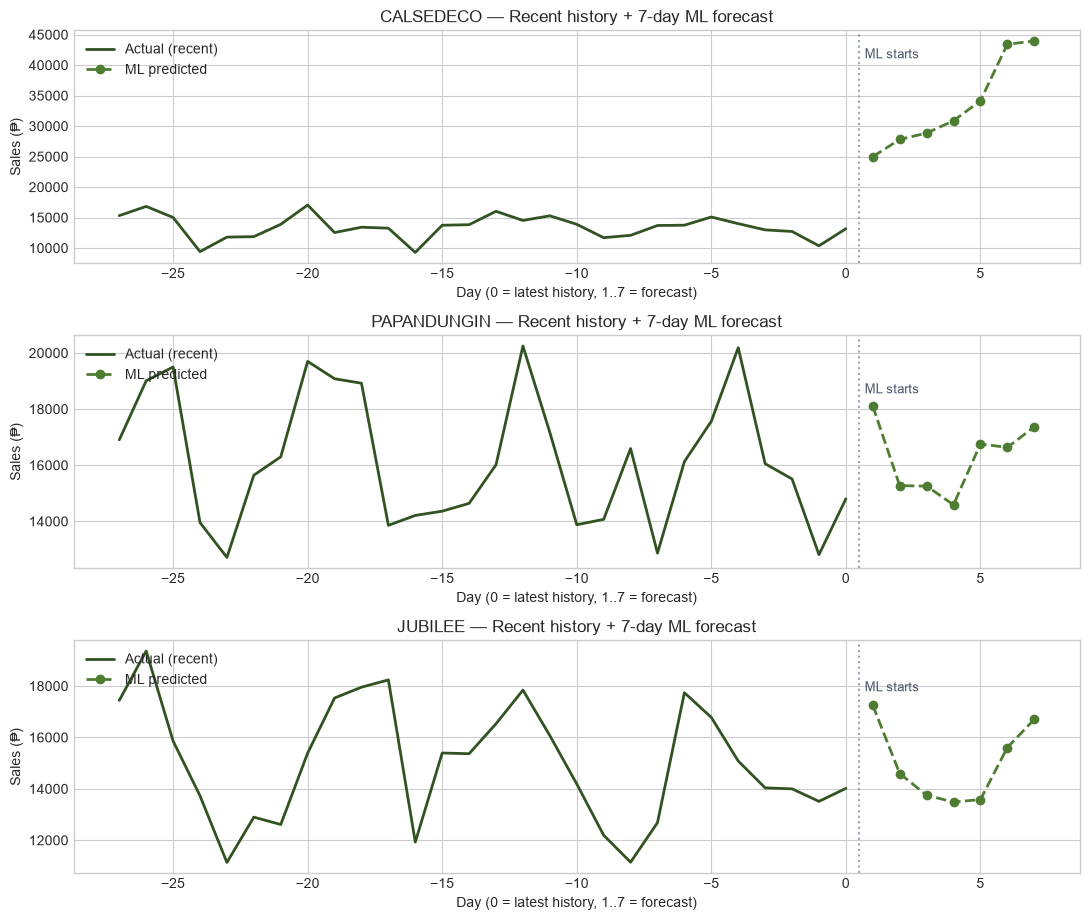

In [35]:
fig, axes = plt.subplots(len(results), 1, figsize=(11, 3.1 * len(results)))
if len(results) == 1:
    axes = [axes]

for ax, result in zip(axes, results):
    recent = np.asarray(result["recent"], dtype=float)
    forecast = result["forecaster"].predict_next(recent, horizon=7)
    hist_x = np.arange(-len(recent) + 1, 1)
    fut_x = np.arange(1, 8)
    ax.plot(hist_x, recent, color="#315322", linewidth=2, label="Actual (recent)")
    ax.plot(fut_x, forecast, color="#4E7D32", linewidth=2, linestyle="--", marker="o", label="ML predicted")
    ax.axvline(0.5, color="#94a3b8", linestyle=":", linewidth=1.5)
    ax.text(0.7, ax.get_ylim()[1] * 0.9 if ax.get_ylim()[1] else 1, "ML starts", fontsize=9, color="#475569")
    ax.set_title(f"{result['store_id']} — Recent history + 7-day ML forecast")
    ax.set_xlabel("Day (0 = latest history, 1..7 = forecast)")
    ax.set_ylabel("Sales (₱)")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

### Figure set E — Random Forest feature importance (top signals)
Shows which lag/calendar features the model relies on most.

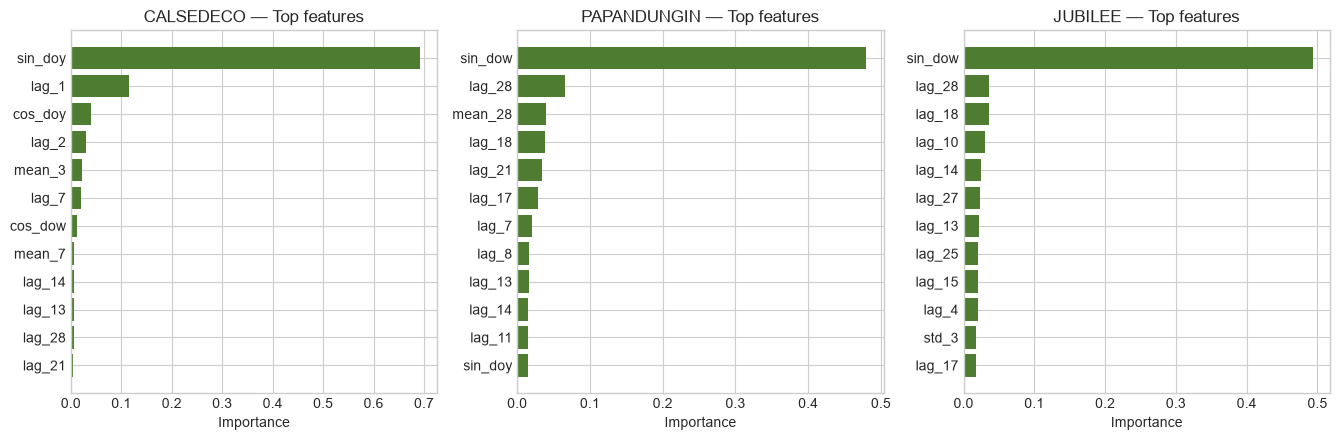

In [36]:
def feature_labels(n_features: int):
    labels = [f"lag_{i}" for i in range(1, 29)]
    for window in (3, 7, 14, 28):
        labels.extend([f"mean_{window}", f"std_{window}"])
    labels.extend(["sin_dow", "cos_dow", "sin_doy", "cos_doy", "is_weekend"])
    if len(labels) < n_features:
        labels.extend([f"feat_{i}" for i in range(len(labels), n_features)])
    return labels[:n_features]

fig, axes = plt.subplots(1, len(results), figsize=(4.5 * len(results), 4.5))
if len(results) == 1:
    axes = [axes]

for ax, result in zip(axes, results):
    model = result["forecaster"].model
    importances = np.asarray(model.feature_importances_, dtype=float)
    labels = feature_labels(len(importances))
    order = np.argsort(importances)[-12:]  # top 12
    ax.barh(np.array(labels)[order], importances[order], color="#4E7D32")
    ax.set_title(f"{result['store_id']} — Top features")
    ax.set_xlabel("Importance")

plt.tight_layout()
plt.show()

## 7. Confirm saved model artifacts

These files are what the Backend loads via `predict_sales.py`.

In [37]:
artifacts = []
for path in sorted(MODELS_DIR.glob("sales_forecaster_store_*.joblib")):
    payload = joblib.load(path)
    config = payload.get("config") or {}
    artifacts.append({
        "file": path.name,
        "bytes": path.stat().st_size,
        "n_lags": config.get("n_lags"),
        "feature_mode": config.get("feature_mode"),
        "n_estimators": config.get("n_estimators"),
        "ml_weight": config.get("ml_weight"),
    })
display(pd.DataFrame(artifacts))
print("\nTraining complete. Models are ready for the Kadiwa Forecasting page.")

,file,bytes,n_lags,feature_mode,n_estimators,ml_weight
0,sales_forecaster_store_CALSEDECO.joblib,3413842,28,calendar,300,0.8
1,sales_forecaster_store_JUBILEE.joblib,1500082,28,calendar,600,1.0
2,sales_forecaster_store_PAPANDUNGIN.joblib,1499650,28,calendar,600,0.8



Training complete. Models are ready for the Kadiwa Forecasting page.


## Capstone screenshot checklist (from THIS notebook)

You now have **more graphs** (Innovet-style multiple figures):

1. Title + Capstone ML notes
2. Dataset table / store stats
3. Combined historical sales chart
4. **Figure set A** — per-store sales lines + distributions
5. Feature matrix preview
6. Training logs + accuracy table
7. **Figure set B** — accuracy / R² bar charts
8. **Section 5** — Actual vs ML predicted (3 stores)
9. **Figure set C** — scatter + residual error graphs
10. **Section 6** — 7-day forecast charts
11. **Figure set D** — history + forecast combined ("ML starts")
12. **Figure set E** — Random Forest feature importance
13. Saved `.joblib` artifacts table

Manuscript draft: `kadiwa/docs/Kadiwa_ML_Chapter_Sales_Forecasting.md`

**Re-run all cells** (kernel: Python / Kadiwa ML) so every new graph renders.